In [149]:
import matplotlib
import numpy as np
import pandas as pd
from narwhals import Int64
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor, HistGradientBoostingRegressor, HistGradientBoostingClassifier
from sklearn.metrics import make_scorer, brier_score_loss
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer, SimpleImputer
from sklearn.model_selection import StratifiedKFold, cross_validate, GridSearchCV, ParameterGrid
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
import matplotlib.pyplot as plt
from sklearn.base import clone

# 1. Load data

In [179]:
train_df = pd.read_csv(r"C:\Users\gelet\PycharmProjects\stop-and-search\data\cleaned_data\stop_search_train1.csv", index_col=0)

# 2. Preprocess

In [180]:
# Dropping unnecessary columns for modeling
train_date = train_df["event_dt"]
train_df = train_df.drop(["event_dt", "orig_age", "vital_flag", "orig_height", "orig_weight", "BMI", "year", "Zone", "Latitude", "Longitude", "SubjectID"], axis = 1)

# Unfloating zip code
train_df["Zip"] = train_df["Zip"].astype("Int64")

# Defining categorical columns
cat_cols = ["SubjectRace", "Zip", "District"]
# Defining discrete/numerical columns
dis_cols = ["SubjectGender", "SubjectAge", "SubjectHeight", "SubjectWeight", "isLA","VehicleYear", "SubjectHasPhotoID", "hour", "night", "isDriver"]
# Numerical columns we would like to scale
scale_cols = ["SubjectAge", "SubjectHeight", "SubjectWeight", "VehicleYear", "hour"]
# Binary columns
bin_cols = ["SubjectGender", "isLA", "SubjectHasPhotoID", "night", "isDriver"]

# Converting variables into strings
train_df[cat_cols] = train_df[cat_cols].astype(str)

In [209]:
target = "search_occurred"
X_train = train_df.drop([target], axis = 1)[cat_cols + dis_cols]
y_train = train_df[target]

# 3. Define classes and functions for k-fold preprocessing

In [210]:
class CatBinner(BaseEstimator, TransformerMixin):
    def __init__(self, cols, min_freq=0.01, fill_value="Other"):
        self.cols = cols
        self.min_freq = min_freq
        self.fill_value = fill_value

    def fit(self, X, y=None):
        self.keep_labels = {}
        for c in self.cols:
            freq = X[c].value_counts(normalize=True)
            self.keep_labels[c] = freq[freq >= self.min_freq].index.tolist()

        return self

    def transform(self, X):
        X_copy = X.copy()
        for c in self.cols:
            labels = self.keep_labels[c]
            X_copy[c] = np.where(X_copy[c].isin(labels) | X_copy[c].isna(), X_copy[c], self.fill_value)
        return X_copy

    def set_output(self, *, transform=None):
        return self

class RoundImputed(BaseEstimator, TransformerMixin):
    def __init__(self, cols):
        self.cols = cols

    def fit(self, X, y=None):
        rounded = X[self.cols].round()
        self.min_ = rounded.min()
        self.max_ = rounded.max()
        return self

    def transform(self, X):
        X_copy = X.copy()
        X_copy[self.cols] = X_copy[self.cols].round().clip(self.min_, self.max_, axis=1)
        return X_copy

    def set_output(self, *, transform=None):
        return self

class OrdEncoder(BaseEstimator, TransformerMixin):
    def __init__(self, cat_cols, inner):
        self.cat_cols = cat_cols
        self.inner = inner

    def _encode(self, X):
        X_enc = X.copy()
        X_enc[self.cat_cols] = self.encoder_.transform(X[self.cat_cols])
        return X_enc

    def _decode(self, X_imp):
        X_dec = X_imp.copy()
        X_dec[self.cat_cols] = self.encoder_.inverse_transform(X_imp[self.cat_cols])
        return X_dec

    def fit_transform(self, X, y=None):
        self.encoder_ = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=np.nan)
        self.encoder_.fit(X[self.cat_cols])
        self.inner_ = clone(self.inner)
        return self._decode(self.inner_.fit_transform(self._encode(X), y))

    def fit(self, X, y=None):
        self.fit_transform(X, y)
        return self

    def transform(self, X):
        return self._decode(self.inner_.transform(self._encode(X)))

    def set_output(self, *, transform=None):
        return self

def build_pipeline(model, cat_cols, dis_cols, scale_cols):
    imputer = IterativeImputer(estimator=HistGradientBoostingRegressor(max_iter=50, random_state=10), skip_complete=True, max_iter=5, tol=1e-2, random_state=10)

    impute = Pipeline([
        ("imputer", imputer),
        ("round", RoundImputed(cols=cat_cols + dis_cols)),
    ])

    impute.set_output(transform="pandas")

    encode = ColumnTransformer([("encode", OneHotEncoder(handle_unknown="ignore"), cat_cols), ("scale", StandardScaler(), scale_cols)], remainder="passthrough", verbose_feature_names_out=False)

    pipeline = Pipeline([
        ("bin", CatBinner(cols=cat_cols, min_freq=0.01, fill_value="Other")),
        ("imputer", OrdEncoder(cat_cols, impute)),
        ("encode", encode),
        ("model", model)
    ], memory="cache_dir")

    return pipeline

## 3a) Define pipeline

In [182]:
# We want to fit lasso logistic regression, and we set max_iter = 1000 to avoid convergence warnings
# Saga solver works for l1_ratio = 1, and it is also faster for large datasets which we have
lr = LogisticRegression(l1_ratio=1, max_iter = 1000, random_state=10, solver="saga")

pipeline = build_pipeline(lr, cat_cols, bin_cols, scale_cols)

# 4. Define grid search parameters and run grid search
## Relevant parameters is C regularization term

In [183]:
# Inverse regularization term C does not scale linearily, so we want to use the base 10 log
param_grid = {"model__C":np.logspace(-4,4,20)}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=10)

grid_search = GridSearchCV(cv = cv, estimator = pipeline, param_grid=param_grid, scoring=["roc_auc", "neg_brier_score", "average_precision"], refit = "average_precision", verbose=2)

grid_search.fit(X_train, y_train)

Fitting 5 folds for each of 20 candidates, totalling 100 fits
[CV] END ....................................model__C=0.0001; total time=   2.7s
[CV] END ....................................model__C=0.0001; total time=   0.9s
[CV] END ....................................model__C=0.0001; total time=   0.8s
[CV] END ....................................model__C=0.0001; total time=   0.9s
[CV] END ....................................model__C=0.0001; total time=   0.8s
[CV] END ....................model__C=0.00026366508987303583; total time=   0.7s
[CV] END ....................model__C=0.00026366508987303583; total time=   0.8s
[CV] END ....................model__C=0.00026366508987303583; total time=   0.8s
[CV] END ....................model__C=0.00026366508987303583; total time=   0.9s
[CV] END ....................model__C=0.00026366508987303583; total time=   0.9s
[CV] END .....................model__C=0.0006951927961775605; total time=   2.3s
[CV] END .....................model__C=0.000695

C:\Users\gelet\PycharmProjects\stop-and-search\.venv\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


[CV] END .........................model__C=4.281332398719396; total time= 1.7min
[CV] END .........................model__C=4.281332398719396; total time= 1.2min
[CV] END .........................model__C=4.281332398719396; total time= 1.5min


C:\Users\gelet\PycharmProjects\stop-and-search\.venv\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


[CV] END .........................model__C=4.281332398719396; total time= 1.4min


C:\Users\gelet\PycharmProjects\stop-and-search\.venv\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


... (16 outputs left out)

[CV] END ........................model__C=29.763514416313132; total time= 1.5min


C:\Users\gelet\PycharmProjects\stop-and-search\.venv\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


[CV] END ........................model__C=29.763514416313132; total time= 1.8min
[CV] END .........................model__C=78.47599703514607; total time=   5.3s
[CV] END .........................model__C=78.47599703514607; total time=   5.9s
[CV] END .........................model__C=78.47599703514607; total time=   5.6s
[CV] END .........................model__C=78.47599703514607; total time=   7.5s
[CV] END .........................model__C=78.47599703514607; total time=   4.8s
[CV] END ..........................model__C=206.913808111479; total time=   4.7s
[CV] END ..........................model__C=206.913808111479; total time=   4.8s
[CV] END ..........................model__C=206.913808111479; total time=   5.2s
[CV] END ..........................model__C=206.913808111479; total time=   3.5s
[CV] END ..........................model__C=206.913808111479; total time=   3.5s
[CV] END .........................model__C=545.5594781168514; total time=   3.7s
[CV] END ...................

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(memo...ver='saga'))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.",{'model__C': array([1.0000...00000000e+04])}
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.","['roc_auc', 'neg_brier_score', ...]"
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",'average_precision'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indic

In [184]:
grid_results = pd.DataFrame(grid_search.cv_results_)

grid_results.to_csv(r"C:\Users\gelet\PycharmProjects\stop-and-search\data\modeling_results\lr_hyp_tuning_grid.csv")

In [203]:
# Implement one-standard-error rule from Elements of Statistical Learning
ind_opt = grid_results["mean_test_average_precision"].idxmax()
mean_opt = grid_results["mean_test_average_precision"].loc[ind_opt]
se_opt = grid_results["std_test_average_precision"].loc[ind_opt]

# Find smallest value of C that is within 1 SD of largest mean
opt_C = min(grid_results["param_model__C"][(mean_opt - se_opt <= grid_results["mean_test_average_precision"]) & (grid_results["mean_test_average_precision"] <= mean_opt + se_opt)])

# Optimal C
print(opt_C)

0.012742749857031334


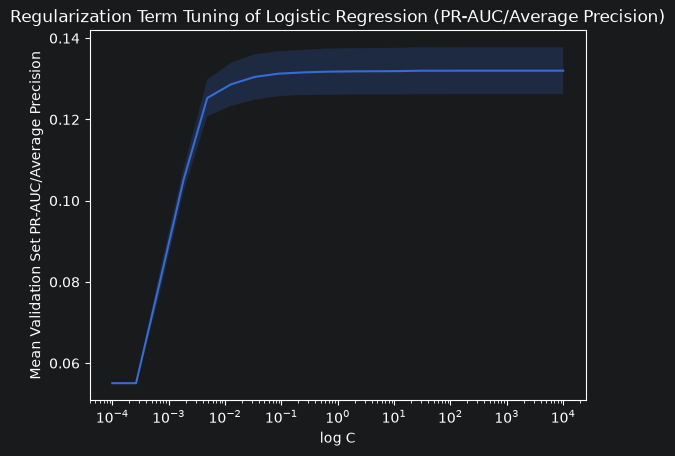

In [204]:
plt.plot(grid_results["param_model__C"], grid_results["mean_test_average_precision"])
plt.fill_between(grid_results["param_model__C"], grid_results["mean_test_average_precision"] - grid_results["std_test_average_precision"], grid_results["mean_test_average_precision"] + grid_results["std_test_average_precision"],  alpha=0.2, label="1 SD Bound"
)
plt.xscale("log")
plt.xlabel("log C")
plt.ylabel("Mean Validation Set PR-AUC/Average Precision")
plt.title("Regularization Term Tuning of Logistic Regression (PR-AUC/Average Precision)")
plt.show()

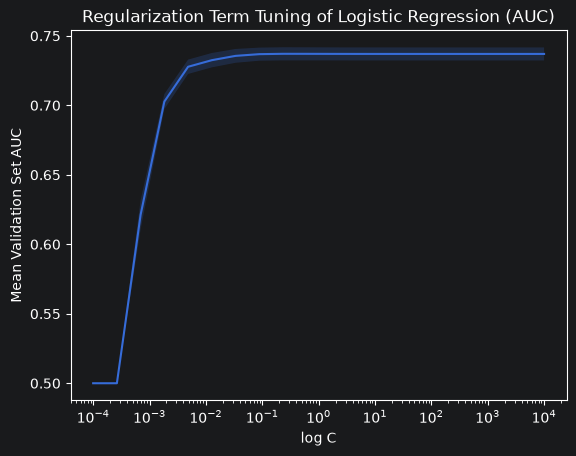

In [205]:
plt.plot(grid_results["param_model__C"], grid_results["mean_test_roc_auc"])
plt.fill_between(grid_results["param_model__C"], grid_results["mean_test_roc_auc"] - grid_results["std_test_roc_auc"], grid_results["mean_test_roc_auc"] + grid_results["std_test_roc_auc"],  alpha=0.2, label="1 SD Bound"
)
plt.xscale("log")
plt.xlabel("log C")
plt.ylabel("Mean Validation Set AUC")
plt.title("Regularization Term Tuning of Logistic Regression (AUC)")
plt.show()

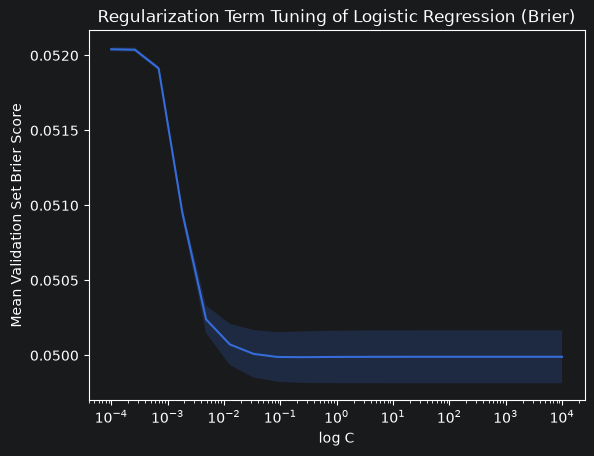

In [206]:
plt.plot(grid_results["param_model__C"], -grid_results["mean_test_neg_brier_score"])
plt.fill_between(grid_results["param_model__C"], -grid_results["mean_test_neg_brier_score"] - grid_results["std_test_neg_brier_score"], -grid_results["mean_test_neg_brier_score"] + grid_results["std_test_neg_brier_score"],  alpha=0.2, label="1 SD Bound"
)
plt.xscale("log")
plt.xlabel("log C")
plt.ylabel("Mean Validation Set Brier Score")
plt.title("Regularization Term Tuning of Logistic Regression (Brier)")
plt.show()

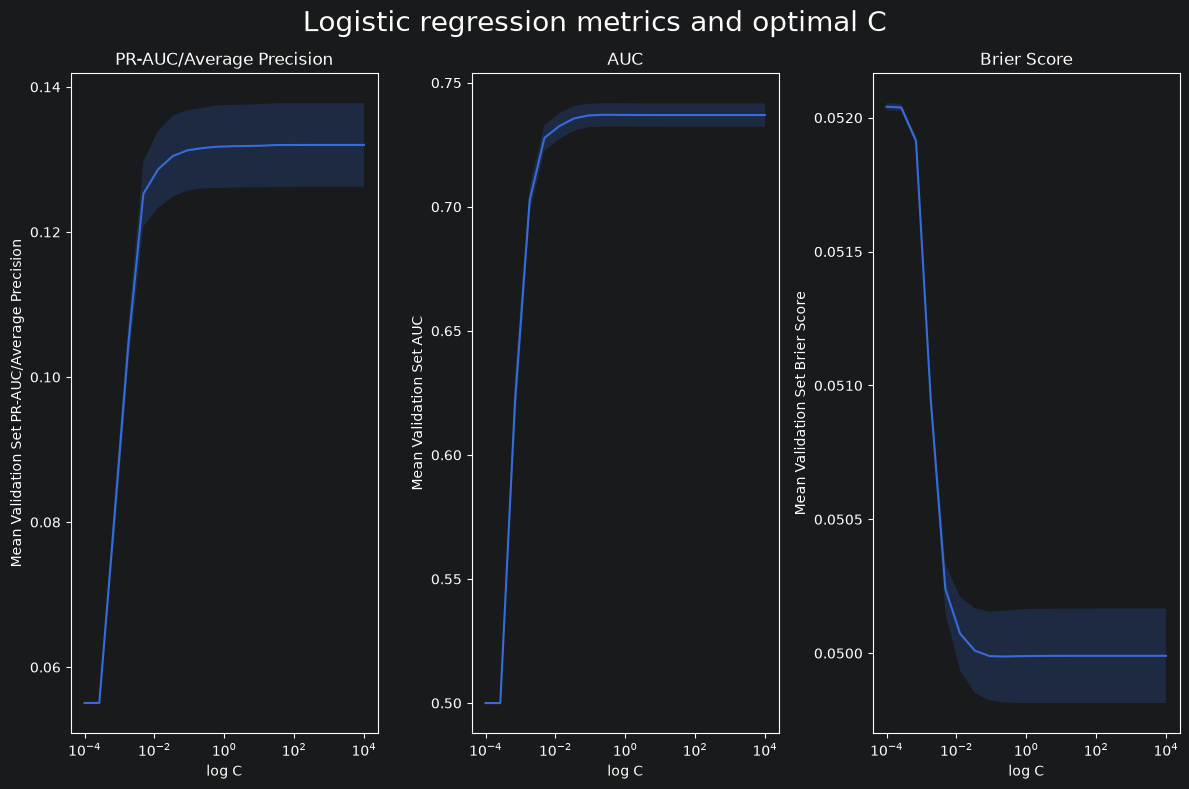

In [208]:
fig, axs = plt.subplots(1, 3, figsize=(12, 8), sharex=True, sharey=False)

axs[0].plot(grid_results["param_model__C"], grid_results["mean_test_average_precision"])
axs[0].fill_between(grid_results["param_model__C"], grid_results["mean_test_average_precision"] - grid_results["std_test_average_precision"], grid_results["mean_test_average_precision"] + grid_results["std_test_average_precision"],  alpha=0.2, label="1 SD Bound"
)
axs[0].set_xlabel("log C")
axs[0].set_ylabel("Mean Validation Set PR-AUC/Average Precision")
axs[0].set_title("PR-AUC/Average Precision")

axs[1].plot(grid_results["param_model__C"], grid_results["mean_test_roc_auc"])
axs[1].fill_between(grid_results["param_model__C"], grid_results["mean_test_roc_auc"] - grid_results["std_test_roc_auc"], grid_results["mean_test_roc_auc"] + grid_results["std_test_roc_auc"],  alpha=0.2, label="1 SD Bound"
)
axs[1].set_ylabel("Mean Validation Set AUC")
axs[1].set_xlabel("log C")
axs[1].set_title("AUC")

axs[2].plot(grid_results["param_model__C"], -grid_results["mean_test_neg_brier_score"])
axs[2].fill_between(grid_results["param_model__C"], -grid_results["mean_test_neg_brier_score"] - grid_results["std_test_neg_brier_score"], -grid_results["mean_test_neg_brier_score"] + grid_results["std_test_neg_brier_score"],  alpha=0.2, label="1 SD Bound"
)
axs[2].set_ylabel("Mean Validation Set Brier Score")
axs[2].set_xlabel("log C")
axs[2].set_title("Brier Score")

plt.xscale("log")
plt.xlabel("log C")
plt.suptitle("Logistic regression metrics and optimal C", size=20)
plt.tight_layout()
plt.show()

## We use PR-AUC/"Average Precision" as our metric to determine the optimal value of C. We then use the "one-standard-error" rule from Elements of Statistical Learning, which picks the simplest/most parsimonious model that is within one SD of the highest cross-val score. Based on this, the optimal C is 0.012742749857031334.